In [28]:
import cv2
import matplotlib.pyplot as plt

def explicit_otsu(image):
    # Ensure the image is in grayscale
    if len(image.shape) > 2:
        image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        
    # Total number of pixels (N)
    N = image.shape[0] * image.shape[1]
    
    # Step 1: Calculate the histogram (number of pixels for each intensity level 0-255)
    hist = cv2.calcHist([image], [0], None, [256], [0, 256])
    
    # Step 2: Calculate the probability of each intensity level (p_i = n_i / N)
    p = [hist[i][0] / N for i in range(256)]
    
    min_sigma_w_sq = float('inf')
    optimal_k = 0
    
    # Step 3: Loop through all possible threshold values k (0 to 255)
    for k in range(256):
        
        # Calculate class probabilities: omega_0 and omega_1
        omega_0 = sum(p[0:k+1])
        omega_1 = sum(p[k+1:256])
        
        # Avoid division by zero if a class has no pixels
        if omega_0 == 0 or omega_1 == 0:
            continue
            
        # Calculate class means: mu_0 and mu_1
        mu_0 = sum(i * p[i] for i in range(0, k+1)) / omega_0
        mu_1 = sum(i * p[i] for i in range(k+1, 256)) / omega_1
        
        # Calculate class variances: sigma_0^2 and sigma_1^2
        sigma_0_sq = sum(((i - mu_0) ** 2) * p[i] for i in range(0, k+1)) / omega_0
        sigma_1_sq = sum(((i - mu_1) ** 2) * p[i] for i in range(k+1, 256)) / omega_1
        
        # Calculate within-class variance: sigma_w^2
        sigma_w_sq = (omega_0 * sigma_0_sq) + (omega_1 * sigma_1_sq)
        
        # Update the optimal threshold if we found a smaller variance
        if sigma_w_sq < min_sigma_w_sq:
            min_sigma_w_sq = sigma_w_sq
            optimal_k = k
            
    # Step 4: Apply the optimal threshold to segment the image
    _, segmented_image = cv2.threshold(image, optimal_k, 255, cv2.THRESH_BINARY)
    
    return optimal_k, segmented_image

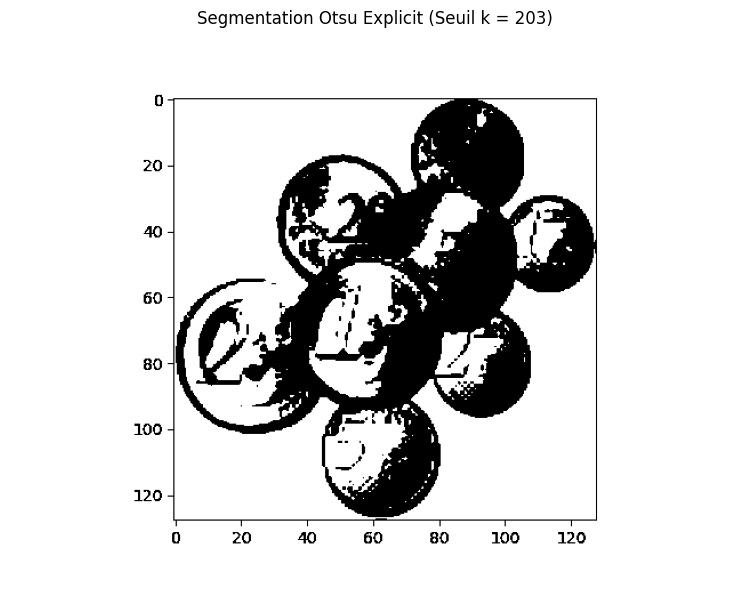

In [30]:
chemin_image = 'euros_nv.png'
image_originale = cv2.imread(chemin_image, cv2.IMREAD_GRAYSCALE)

# Vérifier que l'image a bien été chargée
if image_originale is None:
    print(f"Erreur : Impossible de trouver l'image à l'emplacement '{chemin_image}'")
else:
    # 2. Récupérer les DEUX valeurs retournées par la fonction
    seuil_k, image_segmentee = explicit_otsu(image_originale)

    # 3. Afficher l'image segmentée
    plt.figure(figsize=(12, 6))

    # On peut même ajouter la valeur du seuil dans le titre !
    plt.title(f"Segmentation Otsu Explicit (Seuil k = {seuil_k})") 
    plt.imshow(image_segmentee, cmap='gray')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

In [32]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture

def compare_segmentations(image_path, gmm_components=2):
    # 1. Load Image
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    
    # 2. OTSU Segmentation
    _, otsu_seg = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    
    # 3. Gaussian Modeling (GMM) Segmentation
    # Flatten the image to a 2D array of pixels for sklearn
    pixels = img.reshape(-1, 1)
    
    # Fit the GMM
    gmm = GaussianMixture(n_components=gmm_components, covariance_type='tied', random_state=42)
    gmm.fit(pixels)
    
    # Predict the classes for each pixel
    labels = gmm.predict(pixels)
    
    # Reshape back to image dimensions
    gmm_seg = labels.reshape(img.shape)
    
    # Normalize GMM output to 0-255 for display
    gmm_seg = (255 * (gmm_seg - gmm_seg.min()) / (gmm_seg.max() - gmm_seg.min())).astype(np.uint8)
    
    # 4. Display Results
    plt.figure(figsize=(15, 5))
    
    plt.subplot(1, 3, 1)
    plt.title("Original Image")
    plt.imshow(img, cmap='gray')
    plt.axis('off')
    
    plt.subplot(1, 3, 2)
    plt.title("Otsu's Segmentation")
    plt.imshow(otsu_seg, cmap='gray')
    plt.axis('off')
    
    plt.subplot(1, 3, 3)
    plt.title(f"Gaussian Modeling (K={gmm_components})")
    plt.imshow(gmm_seg, cmap='gray')
    plt.axis('off')
    
    plt.tight_layout()
    plt.show()



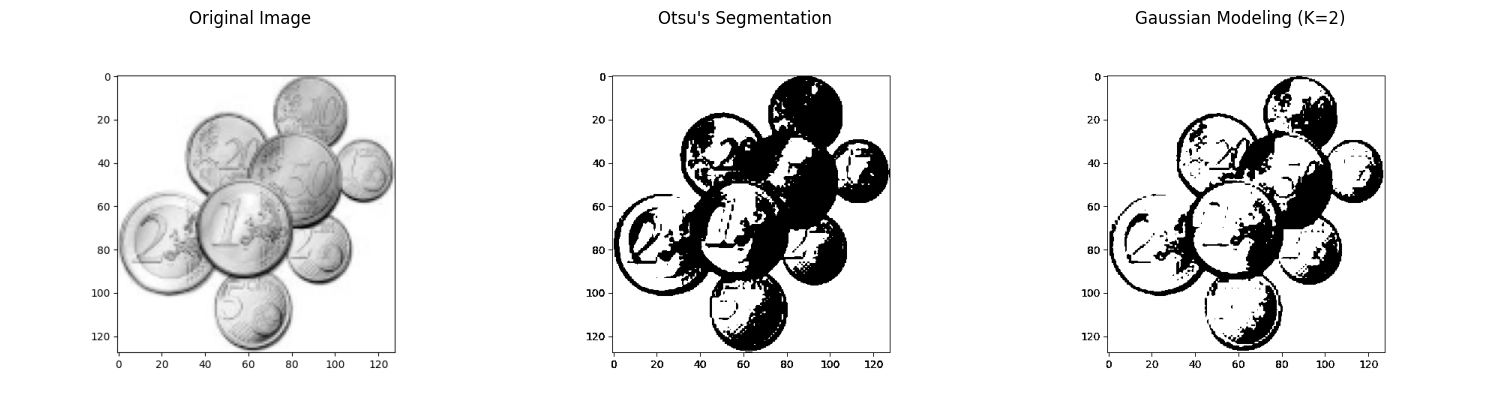

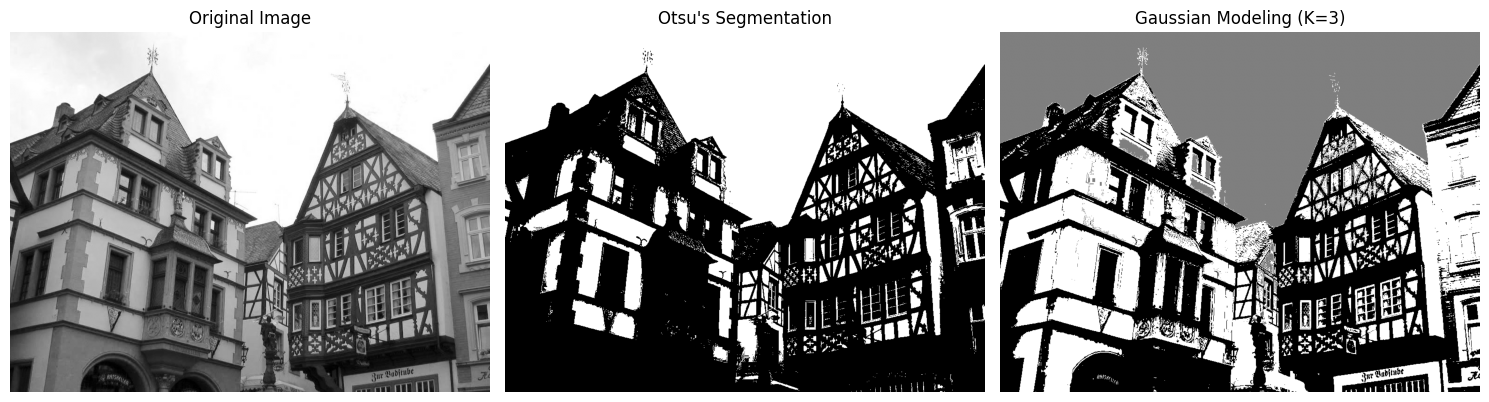

In [34]:
compare_segmentations('euros_nv.png', gmm_components=2)
compare_segmentations('image_otsu.jpg', gmm_components=3) # Higher K for complex scenes

In [35]:
import cv2

def optimized_otsu(image):
    # Ensure grayscale
    if len(image.shape) > 2:
        image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        
    total_pixels = image.shape[0] * image.shape[1]
    
    # Calculate the histogram (counts per intensity level 0-255)
    hist = cv2.calcHist([image], [0], None, [256], [0, 256]).ravel()
    
    # Pre-calculate the total sum of all intensities in the image
    sum_total = sum(i * hist[i] for i in range(256))
    
    sum_class_0 = 0.0  
    weight_class_0 = 0 
    
    max_variance = 0.0  
    optimal_threshold = 0
    
    # Single pass through the histogram (O(L) complexity)
    for k in range(256):
        weight_class_0 += hist[k]
        
        # Skip if Class 0 is empty
        if weight_class_0 == 0:
            continue
            
        weight_class_1 = total_pixels - weight_class_0
        
        # Break if Class 1 is empty (we've processed all actual pixels)
        if weight_class_1 == 0:
            break
            
        # Update running sum for Class 0
        sum_class_0 += k * hist[k]
        
        # Calculate means dynamically
        mean_class_0 = sum_class_0 / weight_class_0
        mean_class_1 = (sum_total - sum_class_0) / weight_class_1
        
        # Calculate between-class variance (sigma_B^2)
        # We use weights (counts) instead of probabilities to save division operations
        variance_between = weight_class_0 * weight_class_1 * ((mean_class_1 - mean_class_0) ** 2)
        
        # Track the maximum variance and its corresponding threshold
        if variance_between > max_variance:
            max_variance = variance_between
            optimal_threshold = k
            
    # Apply the winning threshold
    _, segmented = cv2.threshold(image, optimal_threshold, 255, cv2.THRESH_BINARY)
    
    return optimal_threshold, segmented

Le calcul est terminé. Le seuil optimal d'Otsu est : 203


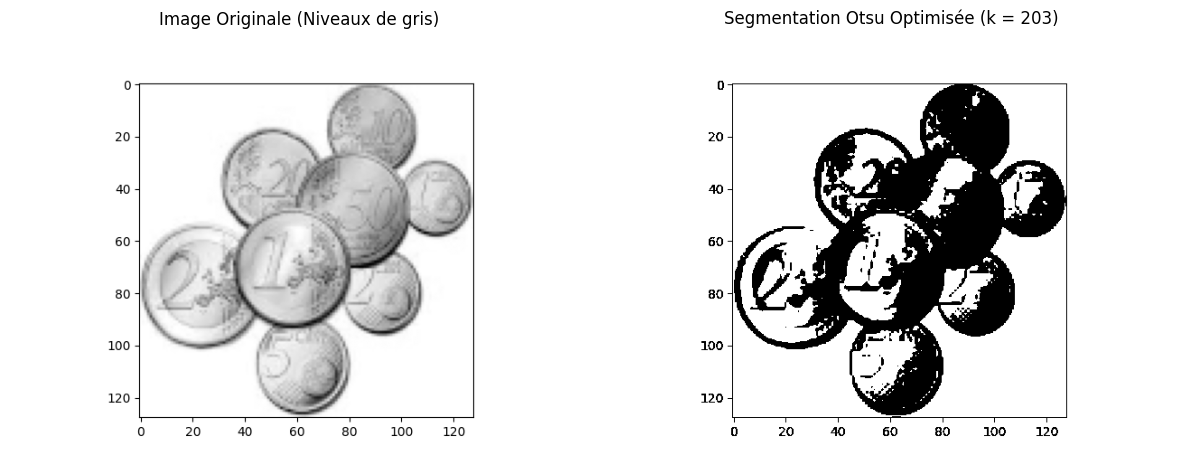

In [36]:
import cv2
import matplotlib.pyplot as plt

# 1. Charger l'image en niveaux de gris
# Assurez-vous que le fichier image se trouve dans le même dossier que votre script
chemin_image = 'euros_nv.png'  # Vous pouvez remplacer par 'image_otsu.jpg'
image = cv2.imread(chemin_image, cv2.IMREAD_GRAYSCALE)

# Vérification de sécurité au cas où l'image est introuvable
if image is None:
    print(f"Erreur : Impossible de charger l'image '{chemin_image}'. Vérifiez le nom ou l'emplacement du fichier.")
else:
    # 2. Appel de la fonction optimisée
    seuil_optimal, image_segmentee = optimized_otsu(image)
    
    # 3. Affichage du seuil calculé dans la console
    print(f"Le calcul est terminé. Le seuil optimal d'Otsu est : {seuil_optimal}")
    
    # 4. Affichage visuel avant/après avec Matplotlib
    plt.figure(figsize=(12, 6))
    
    plt.subplot(1, 2, 1)
    plt.title("Image Originale (Niveaux de gris)")
    plt.imshow(image, cmap='gray')
    plt.axis('off')
    
    plt.subplot(1, 2, 2)
    plt.title(f"Segmentation Otsu Optimisée (k = {seuil_optimal})")
    plt.imshow(image_segmentee, cmap='gray')
    plt.axis('off')
    
    plt.tight_layout()
    plt.show()